# TP 1 · Machine Learning — Cliente
**Inteligencia Artificial · UADE**  
**Grupo 8 · Inteligencia Artificial · 2C 2026**

**Objetivo.** Clasificar la baja de clientes (`Churn`) mediante aprendizaje supervisado binario. Comparamos regresión logística, Random Forest y dos arquitecturas MLP. La clase positiva es `Yes=1`.

El CSV procede exclusivamente de `Tema - Cliente/Cliente.7z` del ZIP de la cátedra. No se sustituyó por una descarga externa. Cada fila representa un cliente. No hay fecha de observación ni horizonte verificable: el experimento estima clasificación retrospectiva; no demuestra anticipación de bajas futuras ni causalidad.

**Recorrido:** datos y partición → EDA de entrenamiento → preprocesamiento → CV y selección → evaluación independiente → redes y conclusiones.

Ejecutar desde la carpeta que contiene `experimento.py`, con el entorno indicado en el README. Las funciones compartidas están en `experimento.py`; aquí se muestran las decisiones, los pasos y sus resultados, sin depender de resultados guardados.

Para Google Colab, consultar la preparación opcional del README: se necesitan también los scripts y el dataset original. La ejecución verificada utiliza el entorno documentado de Windows 11; Colab no forma parte de esa verificación.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "experimento.py").exists() else Path.cwd() / "TP1"
sys.path.insert(0, str(ROOT.resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experimento import (cargar_datos, separar, auditar, describir_variables, graficar_eda,
                         candidatos, entrenar, evaluar, graficar_evaluacion, guardar, NUMERICAS)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## 1. Lectura, contrato y separación de datos
Se verifica la huella SHA-256 y el esquema del archivo original. Convertir espacios vacíos de `TotalCharges` a ausencia y convertir etiquetas a 0/1 son operaciones deterministas, sin estadísticas aprendidas.

Reservamos **20% de prueba estratificada**, `random_state=42`, antes del EDA y de ajustar transformaciones. El 80% restante sirve para entrenamiento y validación cruzada. No se publican IDs en los resultados.

El notebook y el HTML originales describen `Tenure`; el CSV usa **`tenure`**. `TotalCharges` se lee inicialmente como texto por sus espacios vacíos. `SeniorCitizen` es una categoría binaria aunque esté almacenada como entero. `Partner` se interpreta como pareja, no como socio comercial.

In [2]:
raw, datos = cargar_datos()
X_train, X_test, y_train, y_test = separar(datos)
auditoria = auditar(raw, datos, X_train, X_test, y_train, y_test)
print(f"Original: {raw.shape[0]} filas × {raw.shape[1]} columnas")
print(f"Desarrollo: {len(X_train)} clientes; prueba reservada: {len(X_test)} clientes")
print("Duplicados de filas/ID:", auditoria["duplicados_filas"], auditoria["duplicados_id"])
print("Vacíos en TotalCharges:", auditoria["vacios_originales"]["TotalCharges"])
print("Todos esos vacíos tienen tenure=0:", auditoria["faltantes_totalcharges_tenure_cero"])
print("Variables constantes en entrenamiento:", auditoria["constantes_train"])
display(describir_variables(raw, X_train))

Original: 7043 filas × 21 columnas
Desarrollo: 5634 clientes; prueba reservada: 1409 clientes
Duplicados de filas/ID: 0 0
Vacíos en TotalCharges: 11
Todos esos vacíos tienen tenure=0: True
Variables constantes en entrenamiento: []


,variable,tipo_csv,rol,tipo_modelado,valores_distintos_train,faltantes_train
0,customerID,str,identificador excluido,categórica,NaN,NaN
1,gender,str,predictora,categórica,2.0,0.0
2,SeniorCitizen,int64,predictora,categórica,2.0,0.0
3,Partner,str,predictora,categórica,2.0,0.0
4,Dependents,str,predictora,categórica,2.0,0.0
5,tenure,int64,predictora,numérica,73.0,0.0
6,PhoneService,str,predictora,categórica,2.0,0.0
7,MultipleLines,str,predictora,categórica,3.0,0.0
8,InternetService,str,predictora,categórica,3.0,0.0
9,OnlineSecurity,str,predictora,categórica,3.0,0.0


## 2. EDA y decisiones
Exploramos únicamente el 80% de desarrollo. Revisamos dimensiones, nulos, vacíos, categorías, constantes y distribuciones. Los controles de integridad del archivo completo no se usan para ajustar modelos. Una ausencia no se reemplaza por cero: desconocemos la regla de facturación de esos clientes.

Variables: 3 numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`) y 16 categóricas (perfil, servicios, contrato y facturación); `customerID` queda fuera y `Churn` es el objetivo. Se conservan `No phone service` y `No internet service`: distinguen ausencia de servicio de una respuesta `No` a un adicional.

In [3]:
display(pd.DataFrame({"nulos_train": X_train.isna().sum(),
                      "distintos_train": X_train.nunique()}))
display(X_train[NUMERICAS].describe().round(2))
display(pd.DataFrame({"clientes": y_train.value_counts().sort_index(),
                      "proporcion": y_train.value_counts(normalize=True).sort_index()})
        .rename_axis("Churn"))
display(pd.DataFrame({"valores_observados": {c: ", ".join(map(str, sorted(X_train[c].dropna().unique())))
                                           for c in X_train if c not in NUMERICAS}}))

,nulos_train,distintos_train
tenure,0,73
MonthlyCharges,0,1489
TotalCharges,8,5275
gender,0,2
SeniorCitizen,0,2
Partner,0,2
Dependents,0,2
PhoneService,0,2
MultipleLines,0,3
InternetService,0,3


,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5626.00
mean,32.49,64.93,2302.60
std,24.57,30.14,2279.17
min,0.00,18.40,18.85
25%,9.00,35.66,407.28
50%,29.00,70.50,1398.12
75%,55.00,90.00,3838.61
max,72.00,118.75,8684.80


,clientes,proporcion
Churn,,
0,4139,0.734647
1,1495,0.265353


,valores_observados
gender,"Female, Male"
SeniorCitizen,"0, 1"
Partner,"No, Yes"
Dependents,"No, Yes"
PhoneService,"No, Yes"
MultipleLines,"No, No phone service, Yes"
InternetService,"DSL, Fiber optic, No"
OnlineSecurity,"No, No internet service, Yes"
OnlineBackup,"No, No internet service, Yes"
DeviceProtection,"No, No internet service, Yes"


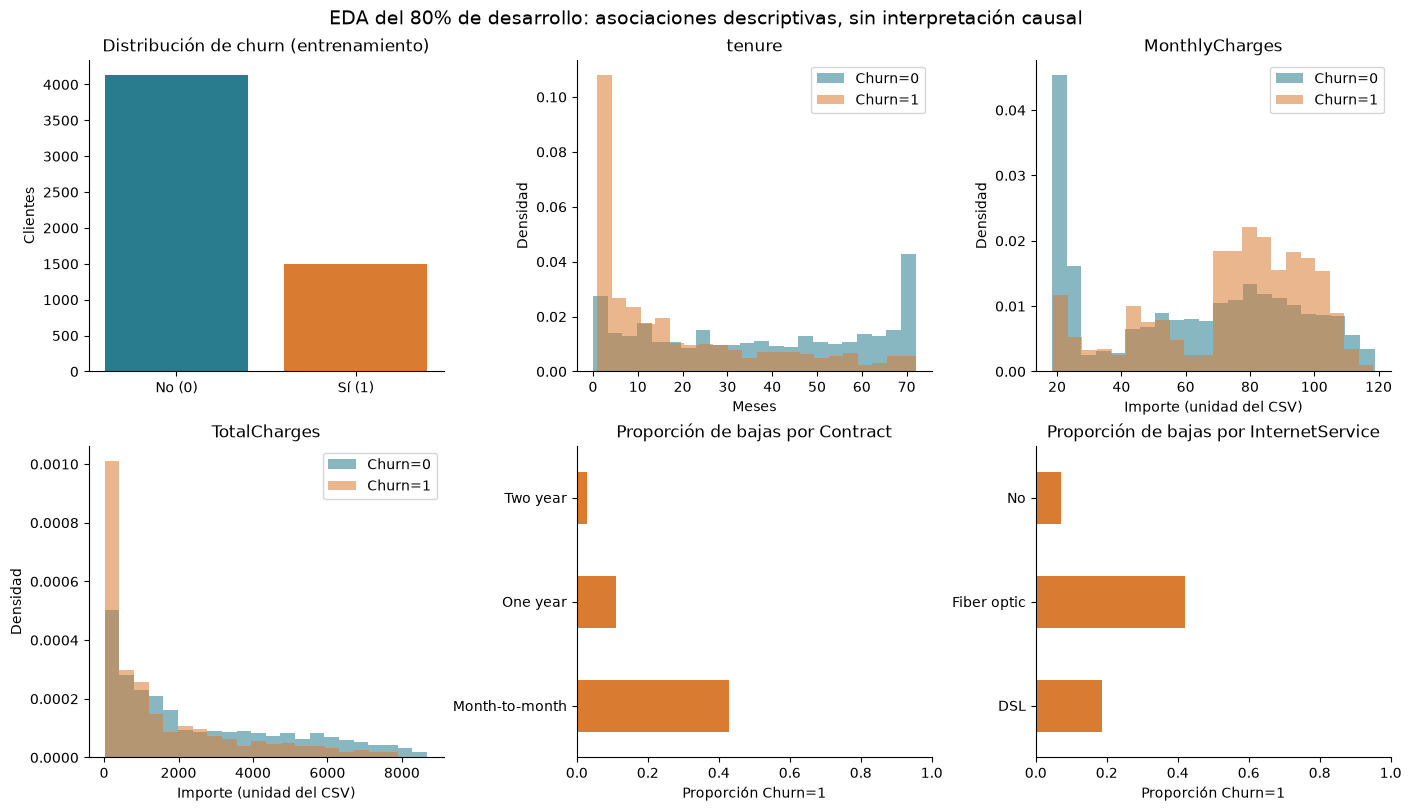

Churn,0,1
Contract,,
Month-to-month,0.573,0.427
One year,0.889,0.111
Two year,0.971,0.029


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.257,0.829
MonthlyCharges,0.257,1.000,0.654
TotalCharges,0.829,0.654,1.000


In [4]:
eda = graficar_eda(X_train, y_train)
display(eda)
plt.close(eda)
display(pd.crosstab(X_train.Contract, y_train, normalize="index").round(3))
display(X_train[NUMERICAS].corr().round(3))

Los contratos mensuales y la antigüedad pueden mostrar asociaciones con churn, sin demostrar causas. Los gráficos permiten revisar su magnitud. La correlación entre facturación acumulada y antigüedad es esperable; no se elimina automáticamente una variable correlacionada: la regularización limita la complejidad y no buscamos interpretar coeficientes como efectos causales.

No se recortan importes extremos sin evidencia de error, no se crean variables derivadas ni se aplica PCA o remuestreo. La clase minoritaria se analiza con recall/F1 y F1 macro; el baseline mayoritario permite ver por qué accuracy sola no alcanza.

## 3. Preprocesamiento sin filtración
Cada candidato es un `Pipeline` con su propio `ColumnTransformer`:

- Numéricas: mediana aprendida en entrenamiento. Regresión logística y MLP agregan `StandardScaler`; Random Forest no necesita escala.
- Categóricas: imputación por moda (defensiva, no se detectaron nulos) y one-hot sin orden artificial, con categorías desconocidas toleradas.
- Se excluye `customerID`, y el objetivo nunca entra al transformador.

Cada fold clona y ajusta el pipeline solamente con su porción de entrenamiento. Las medianas, medias, desviaciones y categorías del fold de validación o del test no participan en ese ajuste. La matriz densa es pequeña para este dataset.

In [5]:
especificaciones = candidatos()
display(especificaciones["Logistica"][0])
display(pd.DataFrame([{"modelo": n, "busqueda": str(grid),
                       "capas_ocultas": str(p.named_steps["modelo"].get_params().get("hidden_layer_sizes", "—"))}
                      for n, (p, grid) in especificaciones.items()]))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

,modelo,busqueda,capas_ocultas
0,Logistica,"{'modelo__C': [0.1, 1.0]}",—
1,RandomForest,"{'modelo__max_depth': [8, None]}",—
2,MLP_1_capa,"{'modelo__alpha': [0.001, 0.01]}","(32,)"
3,MLP_2_capas,"{'modelo__alpha': [0.001, 0.01]}","(32, 16)"


## 4. Modelos, entrenamiento y validación
**Regresión logística:** modela una probabilidad con sigmoide aplicada a una combinación lineal; regularización L2, `C=0.1 o 1`. Es simple y permite estudiar asociaciones, pero limita las interacciones no lineales.

**Random Forest:** 200 árboles, bootstrap y subconjuntos aleatorios de características. Promedia probabilidades de los árboles; no elige solamente el mejor árbol. Probamos profundidad 8 o sin límite, con al menos 5 muestras por hoja. Captura interacciones, aunque es menos transparente y puede sobreajustar.

**MLP:** entrada one-hot más numéricas escaladas → **32** o **32 y 16** neuronas ocultas ReLU → una salida sigmoide. Adam, tasa inicial 0.001, mini-batches de 64, máximo 300 épocas. Probamos `alpha=0.001 o 0.01` (L2). No usamos parada con validación interna: se detiene si la pérdida de entrenamiento no mejora al menos 0.0001 durante más de 20 épocas, o al llegar al máximo. La regularización, las arquitecturas pequeñas y el límite de épocas restringen el sobreajuste; su efecto se evalúa con CV.

**Protocolo fijado antes del test:** 3 folds estratificados mezclados con semilla 42. En cada iteración se usa 2/3 del desarrollo para entrenar y 1/3 para validar. Son 8 configuraciones × 3 folds = 24 ajustes, más 4 ajustes finales. Elegimos el máximo F1 macro medio; empates exactos conservan el orden de menor complejidad declarado. La desviación entre folds describe variabilidad, no es un intervalo de confianza. La media ganadora puede tener optimismo por selección; la prueba independiente sirve como control final.

F1 combina precision y recall: `2PR/(P+R)`. F1 macro promedia el F1 de las dos clases con igual peso. Precision de churn mide la proporción de bajas entre alertas; recall mide cuántas bajas detectamos. Todos usan **umbral fijo 0.5**, sin ajuste con test.

In [6]:
modelos, cv, resumen, elegido, avisos = entrenar(X_train, y_train)
display(cv.round(4))
display(resumen.round(4))
print("Modelo seleccionado exclusivamente por validación:", elegido)
print("Avisos de entrenamiento:", avisos)

Validación: Logistica


Validación: RandomForest


Validación: MLP_1_capa


Validación: MLP_2_capas


,modelo,parametros,seleccionado_en_familia,cv_f1_macro,cv_f1_macro_std,train_f1_macro,...,cv_recall_churn,cv_accuracy,fit_medio_s,fold_1_f1_macro,fold_2_f1_macro,fold_3_f1_macro
0,Logistica,"{""modelo__C"": 0.1}",False,0.7313,0.0107,0.7348,...,0.5405,0.8028,0.0381,0.7216,0.7261,0.7461
1,Logistica,"{""modelo__C"": 1.0}",True,0.7325,0.0115,0.7375,...,0.5458,0.8030,0.0401,0.7200,0.7298,0.7478
2,RandomForest,"{""modelo__max_depth"": 8}",True,0.7239,0.0065,0.7681,...,0.4997,0.8042,0.4770,0.7153,0.7308,0.7257
3,RandomForest,"{""modelo__max_depth"": null}",False,0.7161,0.0061,0.8124,...,0.4863,0.7994,0.5359,0.7094,0.7241,0.7149
4,MLP_1_capa,"{""modelo__alpha"": 0.001}",False,0.7016,0.0153,0.7968,...,0.4990,0.7815,4.4892,0.6829,0.7013,0.7205
5,MLP_1_capa,"{""modelo__alpha"": 0.01}",True,0.7054,0.0075,0.7951,...,0.4970,0.7858,4.7283,0.6973,0.7034,0.7154
6,MLP_2_capas,"{""modelo__alpha"": 0.001}",False,0.6760,0.0074,0.8591,...,0.4762,0.7593,6.1064,0.6751,0.6675,0.6856
7,MLP_2_capas,"{""modelo__alpha"": 0.01}",True,0.6860,0.0098,0.8587,...,0.4889,0.7673,6.3632,0.6743,0.6853,0.6983


,modelo,parametros,cv_f1_macro,cv_f1_macro_std,train_f1_macro,busqueda_y_refit_s,refit_s
0,Logistica,"{""modelo__C"": 1.0}",0.7325,0.0115,0.7375,0.5420,0.0436
1,RandomForest,"{""modelo__max_depth"": 8}",0.7239,0.0065,0.7681,4.4540,0.6231
2,MLP_1_capa,"{""modelo__alpha"": 0.01}",0.7054,0.0075,0.7951,35.2855,7.3785
3,MLP_2_capas,"{""modelo__alpha"": 0.01}",0.6860,0.0098,0.8587,47.4751,9.7806


Modelo seleccionado exclusivamente por validación: Logistica
Avisos de entrenamiento: {'Logistica': [], 'RandomForest': [], 'MLP_1_capa': ["Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet."], 'MLP_2_capas': ["Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet."]}


## 5. Evaluación final sobre la misma prueba
Con configuraciones y ganador ya fijados, se evalúa cada pipeline una vez sobre los mismos clientes de prueba. El baseline `DummyClassifier` predice siempre la clase mayoritaria. No se modifica la recomendación según cuál obtenga el mejor test.

ROC-AUC evalúa ordenamiento sobre umbrales; average precision resume la curva precision-recall y es útil para la minoritaria. Son complementos: no reemplazan las métricas al umbral fijado. Los tiempos corresponden a esta máquina y no a un benchmark universal.

,modelo,accuracy,precision_churn,recall_churn,f1_churn,f1_macro,roc_auc,average_precision
0,Dummy_mayoritaria,0.7346,0.0000,0.0000,0.0000,0.4235,0.5000,0.2654
1,Logistica,0.8055,0.6572,0.5588,0.6040,0.7376,0.8419,0.6338
2,RandomForest,0.8006,0.6655,0.5000,0.5710,0.7205,0.8438,0.6593
3,MLP_1_capa,0.7672,0.5757,0.4679,0.5162,0.6815,0.8232,0.6066
4,MLP_2_capas,0.7537,0.5345,0.5588,0.5464,0.6887,0.7941,0.5637


,precision,recall,f1-score,support
No,0.8488,0.8947,0.8711,1035.0000
Yes,0.6572,0.5588,0.6040,374.0000
accuracy,0.8055,0.8055,0.8055,0.8055
macro avg,0.7530,0.7268,0.7376,1409.0000
weighted avg,0.7979,0.8055,0.8002,1409.0000


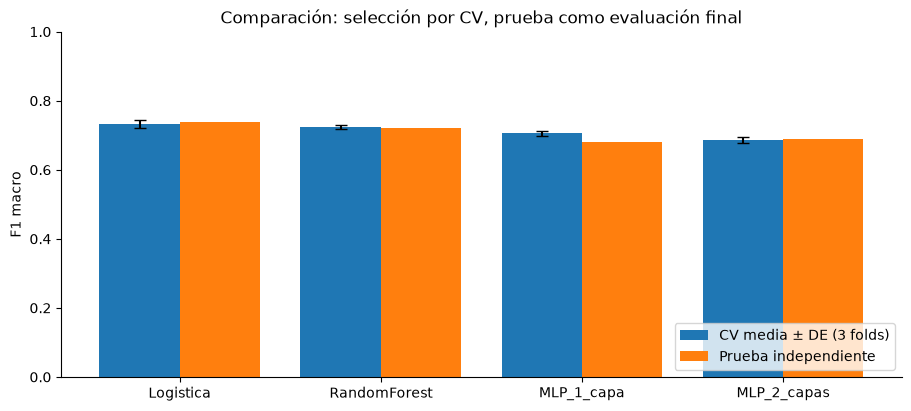

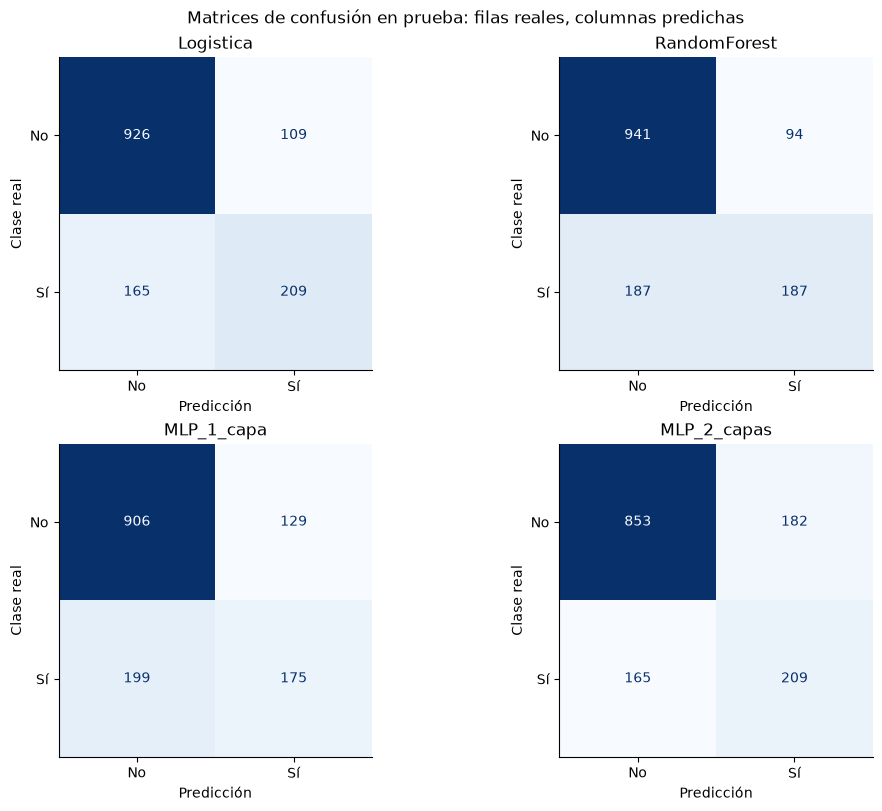

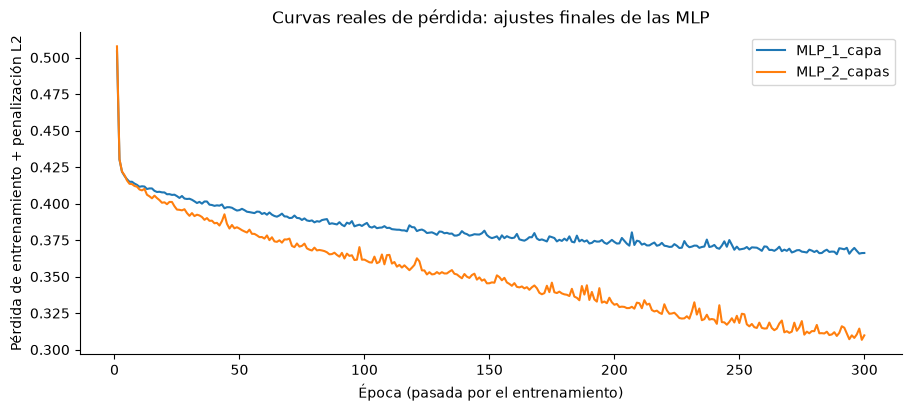

In [7]:
prueba, matrices, reportes, predicciones = evaluar(modelos, X_train, y_train, X_test, y_test)
display(prueba.round(4))
display(pd.DataFrame(reportes[elegido]).T.round(4))
figuras = graficar_evaluacion(resumen, prueba, matrices, modelos)
for nombre in ["comparacion", "confusion"]:
    display(figuras[nombre])
    plt.close(figuras[nombre])

## 6. Redes neuronales y retropropagación
Una capa calcula $z^{(l)}=W^{(l)}a^{(l-1)}+b^{(l)}$ y $a^{(l)}=\mathrm{ReLU}(z^{(l)})$. La salida binaria usa $p=\sigma(z)$ y entropía cruzada $-[y\log p+(1-y)\log(1-p)]$, más penalización L2.

En cada mini-batch: (1) propagación hacia adelante; (2) cálculo de pérdida; (3) retropropagación por regla de la cadena para obtener derivadas respecto de pesos y sesgos; (4) actualización con Adam, que usa momentos de los gradientes y tasas adaptativas. El esquema de descenso básico es $w\leftarrow w-\eta\nabla_w L$; Adam modifica ese paso usando dichos momentos. **Backprop calcula gradientes; el optimizador actualiza los parámetros.** Una época recorre el conjunto de entrenamiento.

La segunda capa permite representar composiciones no lineales, pero aumenta parámetros, costo y riesgo de sobreajuste. La comparación cambia tanto profundidad como cantidad de parámetros, por lo que no aísla un efecto causal de profundidad. La curva muestra pérdida de entrenamiento real, no error de prueba ni demostración por sí sola de generalización. Se usa la implementación estándar de scikit-learn, sin reprogramar backpropagation.

,modelo,entradas,ocultas,salidas,activacion_salida,epocas,alpha,parametros
0,MLP_1_capa,46,"(32,)",1,logistic,300,0.01,1537
1,MLP_2_capas,46,"(32, 16)",1,logistic,300,0.01,2049


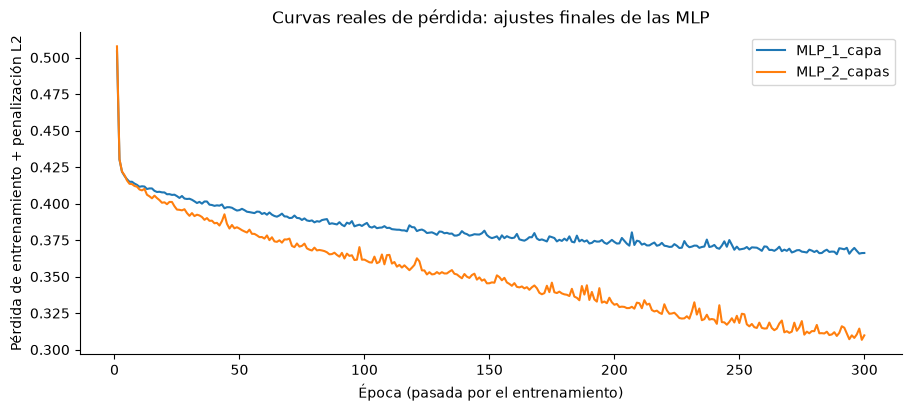

In [8]:
redes = []
for nombre, pipeline in modelos.items():
    m = pipeline.named_steps["modelo"]
    if hasattr(m, "loss_curve_"):
        redes.append({"modelo": nombre, "entradas": m.n_features_in_, "ocultas": m.hidden_layer_sizes,
                      "salidas": m.n_outputs_, "activacion_salida": m.out_activation_,
                      "epocas": m.n_iter_, "alpha": m.alpha,
                      "parametros": sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)})
display(pd.DataFrame(redes))
display(figuras["perdida_mlp"])
plt.close(figuras["perdida_mlp"])

## 7. Recomendación, límites y resultados reproducibles
La recomendación queda determinada por CV. Se revisan también brecha entrenamiento-validación, interpretabilidad, tiempos y complejidad. Una diferencia pequeña entre medias no demuestra superioridad estadística.

Limitaciones: una sola partición externa y semilla; búsqueda pequeña; sin intervalos de confianza ni evaluación temporal; ausencia de horizonte de baja y de verificación del momento de captura de las variables; posible cambio de población; no hay costos de intervención para optimizar umbral; `gender` y `SeniorCitizen` requieren revisión de equidad antes de un uso real. Los datos no prueban que una acción de retención evite una baja.

Para uso futuro habría que verificar que contratos, antigüedad e importes estén disponibles antes de la baja y validar en una cohorte posterior. Esta notebook es evidencia académica, no una validación operacional.

**Lectura de esta ejecución.** Logística obtuvo el mayor F1 macro de CV y el menor tiempo de ajuste final. La brecha train–CV es aproximadamente 0.0050, frente a 0.0897 en la MLP de una capa y 0.1727 en la de dos capas. Las dos MLP alcanzaron el máximo de 300 épocas y emitieron `ConvergenceWarning`: no se declara convergencia del optimizador. Sus scores son los obtenidos con ese presupuesto fijado. No se amplía ni ajusta el entrenamiento después de observar la prueba; la búsqueda neuronal limitada es una limitación del estudio.

In [9]:
fila = prueba.set_index("modelo").loc[elegido]
ganador_cv = resumen.set_index("modelo").loc[elegido]
display(Markdown(f"**Seleccionado por CV: {elegido}.** F1 macro CV: {ganador_cv.cv_f1_macro:.4f} ± {ganador_cv.cv_f1_macro_std:.4f}. "
                 f"En prueba: accuracy {fila.accuracy:.4f}, F1 macro {fila.f1_macro:.4f}, "
                 f"precision churn {fila.precision_churn:.4f}, recall churn {fila.recall_churn:.4f} y F1 churn {fila.f1_churn:.4f}."))
display(resumen[["modelo", "train_f1_macro", "cv_f1_macro", "refit_s"]].round(4))
guardar(raw, datos, X_train, X_test, y_train, y_test, modelos, cv, resumen, elegido, avisos,
        prueba, matrices, reportes, predicciones, eda, figuras)
print("Resultados guardados en resultados/. No se serializan modelos entrenados.")

**Seleccionado por CV: Logistica.** F1 macro CV: 0.7325 ± 0.0115. En prueba: accuracy 0.8055, F1 macro 0.7376, precision churn 0.6572, recall churn 0.5588 y F1 churn 0.6040.

,modelo,train_f1_macro,cv_f1_macro,refit_s
0,Logistica,0.7375,0.7325,0.0436
1,RandomForest,0.7681,0.7239,0.6231
2,MLP_1_capa,0.7951,0.7054,7.3785
3,MLP_2_capas,0.8587,0.6860,9.7806


Resultados guardados en resultados/. No se serializan modelos entrenados.


## 8. Referencias

- C221-TPI-MachineLearning.pdf, pp. 1-2. Consigna del TP1, UADE, 2023.
- Dataset_no_te_vayas.ipynb y Dataset_Cliente.html. Diccionario del dataset Cliente.
- 2. Machine Learning.pdf, pp. 13-30, 62-64 y 115-119.
- 3. Ingeniería de las características.pdf, pp. 36-45 y 50-64.
- 4. Deep Learning.pdf, pp. 59-81 y 85-97.

Los materiales de la cátedra se obtienen en WebCampus y no se redistribuyen.
La notebook y el informe académico entregado por separado sirven como soporte
para la exposición grupal.
